# NMSC × UV analysis (Figure 1A, 1B, 1E and Table 1, lung/NMSC columns)

**Question.** Across contiguous US states, does UV exposure change (i) non-melanoma skin cancer (NMSC) incidence and (ii) the age distribution of NMSC (MEDA)?

**What changed relative to the notebook of the first submission** (revision after peer review, Comment 7):

1. **Median formula fixed.** The old cell used `CF` = cumulative total *including* the median class and `f` = a cumulative total instead of the median-class frequency, with `L=85`, `H=5` hard-coded. That forced every state's median to ≈ 84 y (an artifact). Replaced by a bin-width-aware grouped median that locates the median class for every state (`grouped_median`, with unit tests).
2. **Two clearly named age endpoints** instead of one ambiguous "median age":
   * `meda_cases`: median age of *diagnosed cases*, from GBD `Number` (depends on each state's age structure);
   * `meda_profile`: median of the cumulative *age-specific incidence-rate profile* (rate × bin width), which is free of population age structure and is the analogue of the simulated conditional MEDA.
3. **Both sexes combined correctly** (cases summed, population implied by `Number / Rate`) rather than an unweighted mean of male and female rates.
4. **Explicit input checks** (one row per state, single year, single cause, age-standardised / both-sex rows) and a provenance report to cite in Methods.
5. **Uncertainty and sensitivity added:** slope CIs, Spearman correlation, bootstrap CIs for the high-UV / low-UV ratios, sensitivity to the open-ended 95+ bound, thresholds matched to the figure caption.
6. **Legacy reproduction (appendix):** re-runs the old calculation so you can confirm it reproduces the previously reported Fig 1B values (R² = 0.0236, p = 0.292), then compares it with the corrected values.

**Inputs** (place in `data/`, or set `NMSC_DATA_DIR`): the two IHME/GBD CSV exports and the NCI county UV spreadsheet. **Outputs** go to `outputs/`.

## 0. Setup and configuration

In [1]:
import os, re, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("ticks")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- paths: edit here or set NMSC_DATA_DIR / NMSC_OUT_DIR ----
DATA_DIR = Path(os.environ.get("NMSC_DATA_DIR", "data"))
OUT_DIR = Path(os.environ.get("NMSC_OUT_DIR", "outputs"))
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

F_AGE_SPECIFIC = DATA_DIR / "IHME_data_USA_states.csv"            # GBD age-specific Number and Rate (Fig 1B)
F_AGE_STD = DATA_DIR / "IHME-GBD_2023_DATA-05dbcd0f-1.csv"        # GBD age-standardised rate (Fig 1A)
F_UV = DATA_DIR / "uv-county.xlsx"                                # NCI county UV exposure
UV_SHEET = "UV_County_2000-2024"
UV_COL = "UV_ Wh/m² (2020_2024)"

# ---- analysis parameters (all choices that affect results live here) ----
YEAR = 2023              # GBD year; set to None to require a single year in each file
INCLUDE_DC = True        # the previous analysis had 49 locations = 48 states + DC
OPEN_ENDED_UPPER = 100   # upper bound assumed for the open-ended "95+" age class
UV_LOW, UV_HIGH = 4000, 5000   # Wh/m2; low = UV < 4000, high = UV > 5000 (as in the Fig 1 caption)
N_BOOT = 10_000
SEED = 42

print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.13.2 | pandas 2.3.3 | numpy 2.2.5


In [2]:
# State centroids, used only to colour points by latitude (approximate, not used in any statistic).
state_lat = {
    "Alabama": 32.806671, "Arizona": 34.048928, "Arkansas": 34.969704, "California": 36.778259,
    "Colorado": 39.550051, "Connecticut": 41.603221, "Delaware": 38.910833,
    "District of Columbia": 38.9072, "Florida": 27.664827, "Georgia": 32.165623,
    "Idaho": 44.068203, "Illinois": 40.633125, "Indiana": 40.267194, "Iowa": 41.878003,
    "Kansas": 39.011902, "Kentucky": 37.839333, "Louisiana": 31.244823, "Maine": 45.253783,
    "Maryland": 39.045755, "Massachusetts": 42.407211, "Michigan": 44.314844,
    "Minnesota": 46.729553, "Mississippi": 32.354668, "Missouri": 37.964253,
    "Montana": 46.879682, "Nebraska": 41.492537, "Nevada": 38.80261, "New Hampshire": 43.193851,
    "New Jersey": 40.058324, "New Mexico": 34.97273, "New York": 43.299428,
    "North Carolina": 35.759573, "North Dakota": 47.551493, "Ohio": 40.417287,
    "Oklahoma": 35.007752, "Oregon": 43.804133, "Pennsylvania": 41.203323,
    "Rhode Island": 41.580095, "South Carolina": 33.836081, "South Dakota": 44.299782,
    "Tennessee": 35.517491, "Texas": 31.968599, "Utah": 39.32098, "Vermont": 44.558803,
    "Virginia": 37.431573, "Washington": 47.751074, "West Virginia": 38.597626,
    "Wisconsin": 43.78444, "Wyoming": 43.075968,
}
ANALYSIS_STATES = set(state_lat) - (set() if INCLUDE_DC else {"District of Columbia"})
print(f"{len(ANALYSIS_STATES)} locations in the analysis set (Alaska and Hawaii excluded by design).")

49 locations in the analysis set (Alaska and Hawaii excluded by design).


## 1. Helper functions (with unit tests)

`grouped_median` is the standard grouped-data median, `L + (N/2 - CF_before) / f_class × width`, applied to the **correct** median class, with each class using its own width. The last two tests pin down the previous error using Wyoming values printed in the old notebook: the old formula gave 84.13, the correct one gives 87.98.

In [3]:
def parse_age(label, open_upper=OPEN_ENDED_UPPER):
    """GBD age label -> (lower, upper) in years, class = [lower, upper). '95+ years' uses open_upper."""
    s = label.lower().replace("years", "").replace("year", "").strip()
    if s.startswith("<"):
        return 0.0, float(s[1:])
    if s.endswith("+"):
        return float(s[:-1]), float(open_upper)
    lo, hi = s.split("-")
    return float(lo), float(hi) + 1.0


def grouped_median(lo, hi, counts):
    """Median of a distribution given as counts in age classes [lo, hi), uniform within each class."""
    lo, hi, counts = (np.asarray(a, dtype=float) for a in (lo, hi, counts))
    order = np.argsort(lo)
    lo, hi, counts = lo[order], hi[order], counts[order]
    total = counts.sum()
    if not total > 0:
        return np.nan
    cum = np.cumsum(counts)
    i = int(np.searchsorted(cum, total / 2))         # median class
    before = cum[i - 1] if i > 0 else 0.0
    return lo[i] + (total / 2 - before) / counts[i] * (hi[i] - lo[i])


def ols_report(x, y, label):
    x, y = np.asarray(x, float), np.asarray(y, float)
    n = len(x)
    r = stats.linregress(x, y)
    t = stats.t.ppf(0.975, n - 2)
    rho, p_rho = stats.spearmanr(x, y)
    return {"outcome": label, "n": n, "slope": r.slope,
            "slope_CI95_low": r.slope - t * r.stderr, "slope_CI95_high": r.slope + t * r.stderr,
            "R2": r.rvalue ** 2, "p": r.pvalue, "spearman_rho": rho, "spearman_p": p_rho}


def boot_ratio(high, low, n_boot=N_BOOT, seed=SEED):
    """Ratio of group means (high/low) with a percentile bootstrap CI (states resampled within group)."""
    high, low = np.asarray(high, float), np.asarray(low, float)
    rng = np.random.default_rng(seed)
    h = rng.choice(high, (n_boot, len(high))).mean(axis=1)
    l = rng.choice(low, (n_boot, len(low))).mean(axis=1)
    lo_ci, hi_ci = np.percentile(h / l, [2.5, 97.5])
    return high.mean() / low.mean(), lo_ci, hi_ci


def savefig(fig, name):
    for ext in ("svg", "png"):
        fig.savefig(OUT_DIR / "figures" / f"{name}.{ext}", dpi=300, bbox_inches="tight")


# ---- unit tests ----
assert grouped_median([0, 10, 20], [10, 20, 30], [1, 1, 1]) == 15.0
assert abs(grouped_median([0, 10], [10, 20], [3, 1]) - 20 / 3) < 1e-9
assert grouped_median([0, 10], [10, 30], [1, 1]) == 10.0          # unequal widths handled
# Wyoming values from the old notebook output (class sums before 85, 85-89, 90-94, 95+):
wy = grouped_median([0, 85, 90, 95], [85, 90, 95, 100],
                    [23295.923642, 10028.361731, 11773.609407, 13465.135417])
assert abs(wy - 87.98) < 0.01, wy                                  # correct value; the old formula gave 84.13
assert parse_age("<1 year") == (0.0, 1.0) and parse_age("2-4 years") == (2.0, 5.0)
assert parse_age("75-84 years") == (75.0, 85.0) and parse_age("95+ years", 100) == (95.0, 100.0)
print("unit tests passed")

unit tests passed


## 2. Age-specific GBD data → state-level MEDA (Figure 1B)

Cases (`Number`) are summed over sexes. The population of each sex is implied by `Number / Rate × 100,000`, and the both-sex rate is `sum(cases) / sum(population)`. Classes with a zero rate (very young ages) have no implied population; it is imputed from the other sex, which is immaterial because the cases there are zero.

In [4]:
raw = pd.read_csv(F_AGE_SPECIFIC)
required = {"measure", "location", "sex", "age", "cause", "metric", "year", "val"}
assert required <= set(raw.columns), f"missing columns: {required - set(raw.columns)}"

inc = raw[(raw["measure"] == "Incidence") & raw["metric"].isin(["Number", "Rate"])].copy()
if YEAR is not None:
    inc = inc[inc["year"] == YEAR]
assert inc["year"].nunique() == 1, f"several years in file: {inc['year'].unique()}"
assert inc["cause"].nunique() == 1, f"several causes in file: {inc['cause'].unique()}"
assert not inc.duplicated(["location", "sex", "age", "metric"]).any(), "duplicate rows per location/sex/age/metric"

print("cause :", inc["cause"].unique().tolist())
print("year  :", inc["year"].unique().tolist())
print("sexes :", sorted(inc["sex"].unique()))
print("age classes:", sorted(inc["age"].unique(), key=lambda a: parse_age(a)[0]))

wide = inc.pivot(index=["location", "sex", "age"], columns="metric", values="val").reset_index()
wide["pop"] = np.where(wide["Rate"] > 0, wide["Number"] / wide["Rate"] * 1e5, np.nan)
wide["pop"] = wide["pop"].fillna(wide.groupby(["location", "age"])["pop"].transform("mean"))

profile = (wide.groupby(["location", "age"], as_index=False)
               .agg(cases=("Number", "sum"), pop=("pop", "sum")))
profile["rate"] = np.where(profile["pop"] > 0, profile["cases"] / profile["pop"] * 1e5, 0.0)
profile = profile[profile["location"].isin(ANALYSIS_STATES)]
print(f"\n{profile['location'].nunique()} locations, {profile['age'].nunique()} age classes")
profile.head()

cause : ['Non-melanoma skin cancer']
year  : [2023]
sexes : ['Female', 'Male']
age classes: ['<1 year', '2-4 years', '5-14 years', '15-19 years', '20-24 years', '25-29 years', '30-34 years', '35-39 years', '40-44 years', '45-49 years', '50-54 years', '55-59 years', '60-64 years', '65-69 years', '70-74 years', '75-84 years', '85-89 years', '90-94 years', '95+ years']

49 locations, 19 age classes


,location,age,cases,pop,rate
0,Alabama,15-19 years,0.000000,0.000000,0.000000
1,Alabama,2-4 years,0.000000,0.000000,0.000000
2,Alabama,20-24 years,49.427769,350607.803637,14.097738
3,Alabama,25-29 years,121.683008,339900.197005,35.799629
4,Alabama,30-34 years,386.060769,345326.473049,111.795880


In [5]:
def compute_state_meda(profile, open_upper=OPEN_ENDED_UPPER):
    rows = []
    for loc, g in profile.groupby("location"):
        bounds = [parse_age(a, open_upper) for a in g["age"]]
        lo = np.array([b[0] for b in bounds]); hi = np.array([b[1] for b in bounds])
        rows.append({
            "location": loc,
            # median age of diagnosed cases (depends on population age structure)
            "meda_cases": grouped_median(lo, hi, g["cases"].to_numpy()),
            # median of the cumulative age-specific rate profile (rate x class width; population-structure free)
            "meda_profile": grouped_median(lo, hi, g["rate"].to_numpy() * (hi - lo)),
        })
    return pd.DataFrame(rows)

state_meda = compute_state_meda(profile)
state_meda.describe().loc[["count", "min", "mean", "max"]]

,meda_cases,meda_profile
count,49.000000,49.000000
min,70.527621,83.619869
mean,71.524488,84.808242
max,73.551637,85.603745


## 3. Age-standardised incidence rate (Figure 1A)

The export is filtered explicitly to the age-standardised, both-sex rows, and the notebook stops if there is not exactly one row per location. Its printout of `age_name`, `sex_name`, `cause_name` and `year` is what Methods and Table 1 should cite (Comment 7).

In [6]:
asr_raw = pd.read_csv(F_AGE_STD)
asr = asr_raw[(asr_raw["metric_name"] == "Rate") & (asr_raw["measure_name"] == "Incidence")].copy()
asr = asr.rename(columns={"location_name": "location", "val": "asr"})

for col in ["cause_name", "age_name", "sex_name", "year"]:
    if col in asr.columns:
        print(f"{col:11s}:", sorted(asr[col].unique().tolist(), key=str))

if "age_name" in asr.columns:
    asr = asr[asr["age_name"].str.contains("standardi", case=False)]
if "sex_name" in asr.columns:
    asr = asr[asr["sex_name"].str.lower() == "both"]
if "year" in asr.columns and YEAR is not None:
    asr = asr[asr["year"] == YEAR]
asr = asr[asr["location"].isin(ANALYSIS_STATES)]
assert len(asr) > 0, "no rows left after filtering: check age_name / sex_name / year in the export"
assert asr["location"].is_unique, "more than one row per location: the export holds several ages, sexes or years"
print(f"\n{len(asr)} locations with an age-standardised incidence rate")

cause_name : ['Non-melanoma skin cancer']
age_name   : ['Age-standardized']
sex_name   : ['Both']
year       : [2023]

49 locations with an age-standardised incidence rate


## 4. UV exposure

Mean of the county values of the NCI file for 2020–2024, **unweighted** per state (not population- or area-weighted; state this in Methods). Called *UV exposure*, not "UV incidence", to avoid confusion with cancer incidence.

In [7]:
uv_counties = pd.read_excel(F_UV, sheet_name=UV_SHEET)[["STATENAME", UV_COL]].dropna()
uv = (uv_counties.groupby("STATENAME")[UV_COL]
                 .agg(uv="mean", n_counties="size").reset_index()
                 .rename(columns={"STATENAME": "location"}))
uv = uv[uv["location"].isin(ANALYSIS_STATES)]
print(f"{len(uv)} locations with UV data; counties per location: min {uv['n_counties'].min()}, max {uv['n_counties'].max()}")

49 locations with UV data; counties per location: min 1, max 254


## 5. Merge and coverage check

In [8]:
analysis = (uv.merge(asr[["location", "asr"]], on="location", how="inner")
              .merge(state_meda, on="location", how="inner"))
analysis["lat"] = analysis["location"].map(state_lat)
analysis = analysis.sort_values("location").reset_index(drop=True)

for name, df in [("UV", uv), ("age-standardised rate", asr), ("age-specific profile", state_meda)]:
    missing = sorted(ANALYSIS_STATES - set(df["location"]))
    print(f"missing from {name:22s}: {missing if missing else 'none'}")
print(f"\nanalysis set: n = {len(analysis)} locations")
analysis.head()

missing from UV                    : none
missing from age-standardised rate : none
missing from age-specific profile  : none

analysis set: n = 49 locations


,location,uv,n_counties,asr,meda_cases,meda_profile,lat
0,Alabama,4738.606034,67,943.363228,71.173681,84.475623,32.806671
1,Arizona,5785.206517,15,1029.343202,72.788370,84.873072,34.048928
2,Arkansas,4612.112996,75,795.176933,71.621468,84.684417,34.969704
3,California,5386.394048,58,928.717976,71.684386,85.232347,36.778259
4,Colorado,5092.318495,64,955.244108,70.776389,84.760221,39.550051


## 6. UV vs incidence and vs MEDA (Figures 1A and 1B)

Linear regression of each state-level outcome on UV, with the 95% CI of the slope and Spearman correlation as a sensitivity check. Ecological (state-level) evidence only. A non-significant slope is *not* evidence of no effect: judge it by the slope CI against a **prespecified** margin of practical relevance (Comment 6).

In [9]:
regression = pd.DataFrame([
    ols_report(analysis["uv"], analysis[c], c) for c in ["asr", "meda_cases", "meda_profile"]
]).set_index("outcome")
regression

,n,slope,slope_CI95_low,slope_CI95_high,R2,p,spearman_rho,spearman_p
outcome,,,,,,,,
asr,49,0.074952,0.032153,0.117750,0.208917,0.000961,0.399796,0.004426
meda_cases,49,0.000065,-0.000251,0.000380,0.003608,0.681839,-0.143163,0.326425
meda_profile,49,0.000251,0.000025,0.000476,0.095745,0.030504,0.252755,0.079742


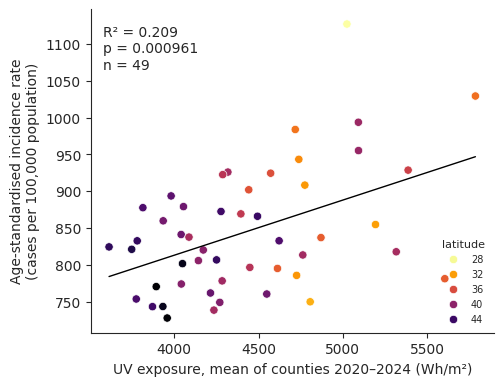

In [10]:
def scatter_fit(df, ycol, ylabel, name, ylim=None):
    fit = stats.linregress(df["uv"], df[ycol])
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    sns.scatterplot(data=df, x="uv", y=ycol, hue="lat", palette="inferno_r", ax=ax)
    xs = np.linspace(df["uv"].min(), df["uv"].max(), 100)
    ax.plot(xs, fit.intercept + fit.slope * xs, color="black", lw=1)
    ax.text(0.03, 0.95, f"R² = {fit.rvalue**2:.3f}\np = {fit.pvalue:.3g}\nn = {len(df)}",
            transform=ax.transAxes, va="top")
    ax.set_xlabel("UV exposure, mean of counties 2020–2024 (Wh/m²)")
    ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)
    ax.legend(title="latitude", fontsize=7, title_fontsize=8, loc="lower right", frameon=False)
    sns.despine()
    savefig(fig, name)
    plt.show()

scatter_fit(analysis, "asr", "Age-standardised incidence rate\n(cases per 100,000 population)", "fig1A_incidence_vs_uv")

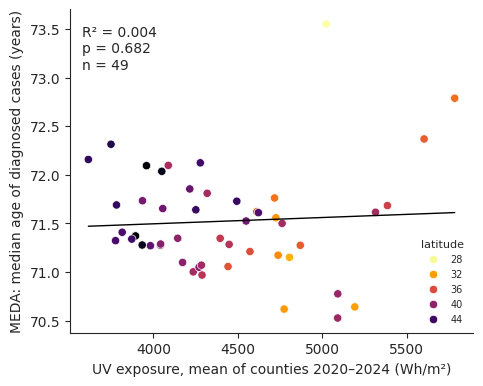

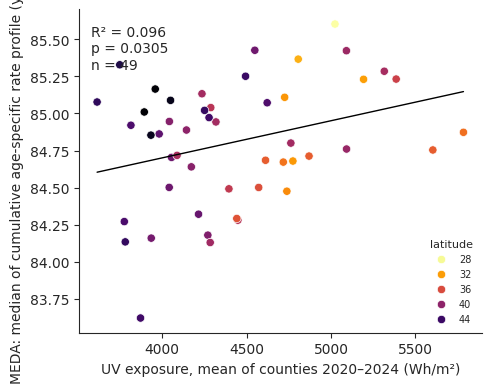

In [11]:
scatter_fit(analysis, "meda_cases", "MEDA: median age of diagnosed cases (years)", "fig1B_meda_cases_vs_uv")
scatter_fit(analysis, "meda_profile", "MEDA: median of cumulative age-specific rate profile (years)", "fig1B_meda_profile_vs_uv")

## 7. High-UV vs low-UV ratios (Figure 1E, NMSC row)

Ratios of group means with bootstrap 95% CIs (states resampled within group), and absolute differences. The thresholds follow the Fig 1 caption (high: UV > 5,000; low: UV < 4,000 Wh/m²).

**Do not** combine these into `rInc / rMEDA`: that quotient adds the magnitudes of two opposite changes and is not a discrepancy measure (Reviewer comment 2). Report the two ratios and their absolute differences separately.

In [12]:
high = analysis[analysis["uv"] > UV_HIGH]
low = analysis[analysis["uv"] < UV_LOW]
print(f"high-UV states: n = {len(high)} | low-UV states: n = {len(low)}")
if min(len(high), len(low)) < 5:
    print("WARNING: very small groups, treat the ratios as descriptive only")

rows = []
for col, label in [("asr", "incidence (age-standardised rate)"),
                   ("meda_cases", "MEDA, median age of cases"),
                   ("meda_profile", "MEDA, cumulative rate profile")]:
    ratio, ci_lo, ci_hi = boot_ratio(high[col], low[col])
    rows.append({"outcome": label, "mean_high": high[col].mean(), "mean_low": low[col].mean(),
                 "ratio_high_over_low": ratio, "ratio_CI95_low": ci_lo, "ratio_CI95_high": ci_hi,
                 "abs_diff_high_minus_low": high[col].mean() - low[col].mean()})
ratios = pd.DataFrame(rows).set_index("outcome")
ratios.round(4)

high-UV states: n = 8 | low-UV states: n = 11


,mean_high,mean_low,ratio_high_over_low,ratio_CI95_low,ratio_CI95_high,abs_diff_high_minus_low
outcome,,,,,,
incidence (age-standardised rate),936.0001,804.3839,1.1636,1.0617,1.2715,131.6162
"MEDA, median age of cases",71.7444,71.6352,1.0015,0.9916,1.0119,0.1092
"MEDA, cumulative rate profile",85.1453,84.6729,1.0056,1.0014,1.0100,0.4725


## 8. Sensitivity to the open-ended 95+ class

The upper bound of the last class is an assumption. The table shows how the MEDA–UV regression changes with it.

In [13]:
rows = []
for upper in (100, 105, 110):
    sm = compute_state_meda(profile, open_upper=upper).merge(uv[["location", "uv"]], on="location")
    for col in ("meda_cases", "meda_profile"):
        r = ols_report(sm["uv"], sm[col], col)
        rows.append({"open_upper": upper, "outcome": col, "mean_meda": sm[col].mean(),
                     "slope": r["slope"], "R2": r["R2"], "p": r["p"]})
pd.DataFrame(rows).round(4)

,open_upper,outcome,mean_meda,slope,R2,p
0,100,meda_cases,71.5245,0.0001,0.0036,0.6818
1,100,meda_profile,84.8082,0.0003,0.0957,0.0305
2,105,meda_cases,71.5245,0.0001,0.0036,0.6818
3,105,meda_profile,87.7507,0.0002,0.0771,0.0534
4,110,meda_cases,71.5245,0.0001,0.0036,0.6818
5,110,meda_profile,90.5751,0.0002,0.0607,0.0878


## Appendix A. Reproduction of the previous (incorrect) median

This re-runs the calculation of the old notebook (unweighted sex average, summed rates, hard-coded `L=85`, `H=5`, `CF` = cumulative up to 85, `f` = cumulative up to 80). It is here so the earlier Fig 1B values can be reproduced and compared with the corrected ones. **Do not use it for results.**

In [14]:
leg = raw[(raw["measure"] == "Incidence") & (raw["metric"] == "Rate")]
if YEAR is not None:
    leg = leg[leg["year"] == YEAR]
leg = leg[["location", "age", "val"]].groupby(["location", "age"], as_index=False).mean()
leg["a"] = (leg["age"].str[:2].str.replace("-", "", regex=False)
                              .str.replace("<", "", regex=False).astype(float))
leg = leg[(leg["a"] > 1) & leg["location"].isin(ANALYSIS_STATES)].sort_values(["location", "a"])
leg["acc"] = leg.groupby("location")["val"].cumsum()

def old_formula(g):
    n = g["acc"].max()
    CF = g.loc[g["a"] <= 85, "acc"].max()
    f = g.loc[g["a"] <= 80, "acc"].max()
    return 85 + (n / 2 - CF) / f * 5

legacy_median = pd.DataFrame([{"location": loc, "meda_legacy": old_formula(g)} for loc, g in leg.groupby("location")])
cmp_ = analysis[["location", "uv", "meda_profile"]].merge(legacy_median, on="location")

old = ols_report(cmp_["uv"], cmp_["meda_legacy"], "meda_legacy")
print(f"legacy medians: min {cmp_['meda_legacy'].min():.2f}, max {cmp_['meda_legacy'].max():.2f}  (spread = formula artifact)")
print(f"corrected rate-profile medians: min {cmp_['meda_profile'].min():.2f}, max {cmp_['meda_profile'].max():.2f}")
print(f"legacy regression on UV: R2 = {old['R2']:.4f}, p = {old['p']:.4f}   (previously reported: R2 = 0.0236, p = 0.292)")

legacy medians: min 83.82, max 84.23  (spread = formula artifact)
corrected rate-profile medians: min 83.62, max 85.60
legacy regression on UV: R2 = 0.0236, p = 0.2922   (previously reported: R2 = 0.0236, p = 0.292)


## 9. Provenance report and saved outputs

The provenance block lists the settings to cite in Methods and in Table 1 / Comment 7 (data source, year, sexes, age classes, number of locations, UV period).

In [15]:
provenance = {
    "gbd_age_specific_file": F_AGE_SPECIFIC.name,
    "gbd_age_standardised_file": F_AGE_STD.name,
    "gbd_cause": sorted(inc["cause"].unique().tolist()),
    "gbd_year": int(inc["year"].iloc[0]),
    "sexes_combined": sorted(inc["sex"].unique().tolist()),
    "age_classes": sorted(inc["age"].unique().tolist(), key=lambda a: parse_age(a)[0]),
    "open_ended_upper_bound": OPEN_ENDED_UPPER,
    "uv_file": F_UV.name, "uv_sheet": UV_SHEET, "uv_column": UV_COL,
    "uv_aggregation": "unweighted mean of county values per state",
    "n_locations": int(len(analysis)), "includes_DC": bool(INCLUDE_DC),
    "uv_thresholds_Wh_m2": {"low_below": UV_LOW, "high_above": UV_HIGH},
    "n_high_uv": int(len(high)), "n_low_uv": int(len(low)),
    "bootstrap": {"n": N_BOOT, "seed": SEED},
}
print(json.dumps(provenance, indent=2))

analysis.to_csv(OUT_DIR / "state_level_results.csv", index=False)
regression.to_csv(OUT_DIR / "regression_summary.csv")
ratios.to_csv(OUT_DIR / "high_vs_low_uv_ratios.csv")
(OUT_DIR / "provenance.json").write_text(json.dumps(provenance, indent=2))
print("\nsaved to", OUT_DIR.resolve())

{
  "gbd_age_specific_file": "IHME_data_USA_states.csv",
  "gbd_age_standardised_file": "IHME-GBD_2023_DATA-05dbcd0f-1.csv",
  "gbd_cause": [
    "Non-melanoma skin cancer"
  ],
  "gbd_year": 2023,
  "sexes_combined": [
    "Female",
    "Male"
  ],
  "age_classes": [
    "<1 year",
    "2-4 years",
    "5-14 years",
    "15-19 years",
    "20-24 years",
    "25-29 years",
    "30-34 years",
    "35-39 years",
    "40-44 years",
    "45-49 years",
    "50-54 years",
    "55-59 years",
    "60-64 years",
    "65-69 years",
    "70-74 years",
    "75-84 years",
    "85-89 years",
    "90-94 years",
    "95+ years"
  ],
  "open_ended_upper_bound": 100,
  "uv_file": "uv-county.xlsx",
  "uv_sheet": "UV_County_2000-2024",
  "uv_column": "UV_ Wh/m\u00b2 (2020_2024)",
  "uv_aggregation": "unweighted mean of county values per state",
  "n_locations": 49,
  "includes_DC": true,
  "uv_thresholds_Wh_m2": {
    "low_below": 4000,
    "high_above": 5000
  },
  "n_high_uv": 8,
  "n_low_uv": 11,
  "bo